##Text preprocessing and Word2Vec embeddings using NLTK and Gensim
**Student Roll Number:** 24BAD039


To implement an LSTM neural network for sentiment analysis using the IMDB Movie Reviews dataset and classify reviews as positive or negative.

##Dataset preparation and text preprocessing

In [2]:
!pip install gensim

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.corpus import brown, stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.probability import FreqDist
from gensim.models import Word2Vec
import string
import re

# Download required NLTK resources
nltk.download("brown")
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("Libraries imported and NLTK resources downloaded.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 43.3 MB/s eta 0:00:00


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries imported and NLTK resources downloaded.


In [3]:
# Select the news category from the Brown Corpus
category = "news"

raw_sentences = brown.sents(categories=category)

print("Selected category:", category)
print("Number of sentences:", len(raw_sentences))

print("\nSample original sentences:")
for sentence in raw_sentences[:5]:
    print(" ".join(sentence))

Selected category: news
Number of sentences: 4623

Sample original sentences:
The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. .
`` Only a relative handful of such reports was received '' , the jury said , `` considering the widespread interest in the election , the number of voters and the size of this city '' .
The jury said it did find that many of Georgia's registration and election laws `` are outmoded or inadequate and

In [4]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

original_text = [" ".join(sentence) for sentence in raw_sentences[:5]]

def preprocess_sentence(sentence):
    sentence = sentence.lower()
    tokens = word_tokenize(sentence)

    processed_tokens = []

    for token in tokens:
        # Retain alphabetic words and remove punctuation/numbers
        if token.isalpha() and token not in stop_words:
            lemma = lemmatizer.lemmatize(token)
            processed_tokens.append(lemma)

    return processed_tokens

# Preserve sentence boundaries for Word2Vec training
processed_sentences = [
    preprocess_sentence(" ".join(sentence))
    for sentence in raw_sentences
]

# Remove empty sentences
processed_sentences = [
    sentence for sentence in processed_sentences if sentence
]

print("Original text:")
for sentence in original_text:
    print(sentence)

print("\nPreprocessed text:")
for sentence in processed_sentences[:5]:
    print(sentence)

print("\nTotal processed sentences:", len(processed_sentences))

Original text:
The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. .
`` Only a relative handful of such reports was received '' , the jury said , `` considering the widespread interest in the election , the number of voters and the size of this city '' .
The jury said it did find that many of Georgia's registration and election laws `` are outmoded or inadequate and often ambiguous '' .

Preprocessed text:
['fulton', 'county', 

##Vocabulary generation and word frequency analysis

In [5]:
# Combine tokens for frequency analysis
all_tokens = [
    word
    for sentence in processed_sentences
    for word in sentence
]

frequency_distribution = FreqDist(all_tokens)
vocabulary = set(all_tokens)

print("Total tokens:", len(all_tokens))
print("Vocabulary size:", len(vocabulary))

print("\nTop 10 most frequent words:")
for word, frequency in frequency_distribution.most_common(10):
    print(f"{word}: {frequency}")

Total tokens: 47682
Vocabulary size: 9896

Top 10 most frequent words:
said: 406
year: 260
would: 249
new: 241
state: 223
one: 222
last: 177
two: 174
first: 158
president: 155


,Word,Frequency
0,said,406
1,year,260
2,would,249
3,new,241
4,state,223
5,one,222
6,last,177
7,two,174
8,first,158
9,president,155


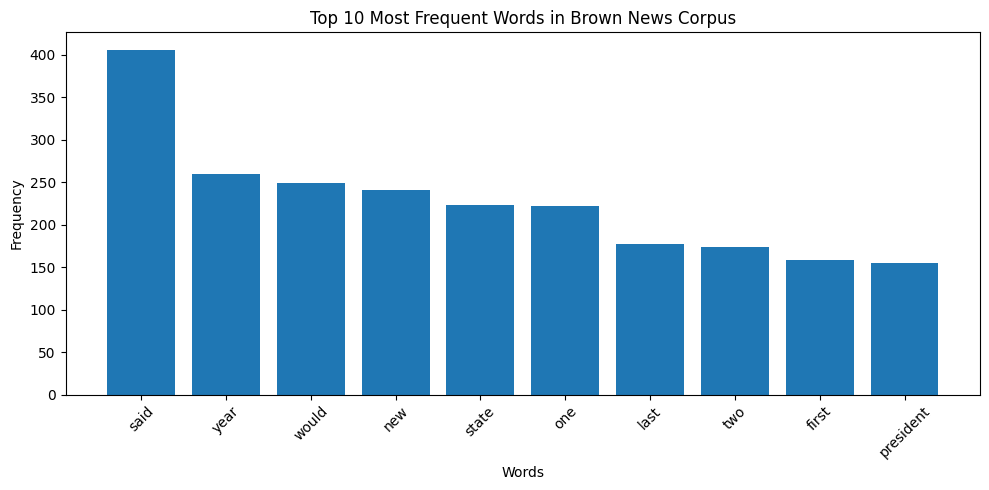

In [6]:
top_words = frequency_distribution.most_common(10)

frequency_df = pd.DataFrame(
    top_words,
    columns=["Word", "Frequency"]
)

display(frequency_df)

plt.figure(figsize=(10, 5))
plt.bar(
    frequency_df["Word"],
    frequency_df["Frequency"]
)
plt.title("Top 10 Most Frequent Words in Brown News Corpus")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##Word embedding generation using Word2Vec

In [7]:
word2vec_model = Word2Vec(
    sentences=processed_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,           # Skip-gram architecture
    workers=4,
    epochs=10,
    seed=42
)

print("Word2Vec model training completed.")
print("Embedding dimension:", word2vec_model.vector_size)
print("Vocabulary size:", len(word2vec_model.wv))

Word2Vec model training completed.
Embedding dimension: 100
Vocabulary size: 5164


In [8]:
# Select a word available in the trained vocabulary
selected_word = "government"

if selected_word not in word2vec_model.wv:
    selected_word = word2vec_model.wv.index_to_key[0]

embedding_vector = word2vec_model.wv[selected_word]

print("Selected word:", selected_word)
print("Embedding vector:")
print(embedding_vector)

print("\nVector dimensions:", embedding_vector.shape)
print("Number of values:", len(embedding_vector))

Selected word: government
Embedding vector:
[-0.03364391 -0.01116964  0.03724362  0.20024383 -0.10133816 -0.08260293
  0.12339694  0.22079043  0.17446621 -0.30425763 -0.38339052  0.00294164
 -0.03837747  0.34175164 -0.08252368 -0.23160256  0.00995546 -0.17562571
 -0.31507757  0.2075622   0.11009888  0.1999029  -0.01192289  0.0919226
 -0.05701254 -0.03282822 -0.17908028  0.26853547 -0.13819116 -0.07414316
 -0.16121283 -0.1334261   0.07858758  0.0547539   0.08223428 -0.18701689
  0.22488388 -0.17635767 -0.11783176 -0.05463624 -0.03646591 -0.08434711
  0.15661803 -0.23951972  0.09054393  0.03266823  0.39723796  0.25583988
  0.364865   -0.37396303 -0.10041387 -0.25859198 -0.1394869   0.01338241
  0.01067303  0.04607352 -0.14212139 -0.02722538 -0.015277    0.15827487
  0.03989172 -0.03996522 -0.21871497  0.08225465  0.09591837  0.0687152
  0.01173624 -0.13128512 -0.35594067 -0.09576838 -0.04123929 -0.01422142
 -0.125176   -0.17729898  0.0278789   0.09341508  0.02552817 -0.23101154
 -0.03063

In [9]:
similar_words = word2vec_model.wv.most_similar(
    selected_word,
    topn=5
)

print(f"Five words most similar to '{selected_word}':")

for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")

Five words most similar to 'government':
nation: 0.9673
federal: 0.9668
department: 0.9662
program: 0.9558
local: 0.9545


##Word similarity analysis

In [10]:
# Select meaningful word pairs from the trained vocabulary
candidate_pairs = [
    ("government", "state"),
    ("man", "woman"),
    ("day", "week")
]

# Keep only pairs whose words exist in the vocabulary
word_pairs = [
    (word1, word2)
    for word1, word2 in candidate_pairs
    if word1 in word2vec_model.wv
    and word2 in word2vec_model.wv
]

if len(word_pairs) < 3:
    print("Some selected words are missing from the vocabulary.")
    print("Choose alternative words from word2vec_model.wv.index_to_key.")

similarity_results = []

for word1, word2 in word_pairs:
    score = word2vec_model.wv.similarity(word1, word2)

    similarity_results.append({
        "Word 1": word1,
        "Word 2": word2,
        "Cosine Similarity": round(float(score), 4)
    })

similarity_df = pd.DataFrame(similarity_results)
display(similarity_df)

if not similarity_df.empty:
    most_similar_pair = similarity_df.loc[
        similarity_df["Cosine Similarity"].idxmax()
    ]

    print(
        "\nMost similar pair:",
        most_similar_pair["Word 1"],
        "and",
        most_similar_pair["Word 2"]
    )
    print(
        "Similarity score:",
        most_similar_pair["Cosine Similarity"]
    )

,Word 1,Word 2,Cosine Similarity
0,government,state,0.9244
1,man,woman,0.9732
2,day,week,0.8728



Most similar pair: man and woman
Similarity score: 0.9732


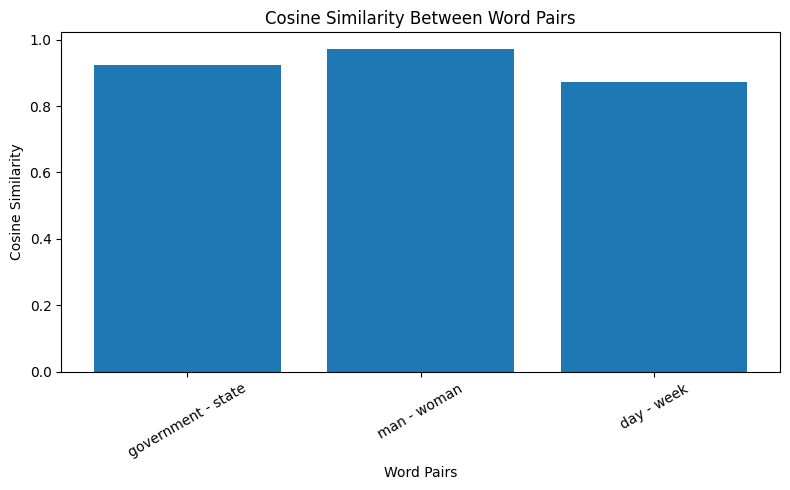

In [11]:
if not similarity_df.empty:
    pair_labels = (
        similarity_df["Word 1"]
        + " - "
        + similarity_df["Word 2"]
    )

    plt.figure(figsize=(8, 5))
    plt.bar(
        pair_labels,
        similarity_df["Cosine Similarity"]
    )
    plt.title("Cosine Similarity Between Word Pairs")
    plt.xlabel("Word Pairs")
    plt.ylabel("Cosine Similarity")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [12]:
print("FINAL OBSERVATIONS")
print("-" * 50)

print("1. Text preprocessing removed punctuation and stop words.")
print("2. Word frequency analysis identified common vocabulary.")
print("3. Word2Vec generated 100-dimensional word embeddings.")
print("4. Cosine similarity measured the closeness of word vectors.")

if not similarity_df.empty:
    print(
        "5. The highest-scoring tested pair was:",
        most_similar_pair["Word 1"],
        "and",
        most_similar_pair["Word 2"]
    )

print(
    "\nNote: Similarity reflects distributional context, "
    "not necessarily exact synonymy."
)

FINAL OBSERVATIONS
--------------------------------------------------
1. Text preprocessing removed punctuation and stop words.
2. Word frequency analysis identified common vocabulary.
3. Word2Vec generated 100-dimensional word embeddings.
4. Cosine similarity measured the closeness of word vectors.
5. The highest-scoring tested pair was: man and woman

Note: Similarity reflects distributional context, not necessarily exact synonymy.
